# Data Preprocessing: Superstore Sales Dataset
Notebook ini memuat tahap pra-pemrosesan data (*Data Understanding & Preprocessing*) untuk dataset transaksi penjualan ritel berskala besar (*Superstore Sales Dataset*).

* **Dataset Asal:** `superstore_sales.csv` (9.818 baris transaksi ritel)
* **Karakteristik Data:** 9.818 transaksi penjualan dan 18 atribut komprehensif mencakup informasi pesanan, pelanggan, geografi, produk, dan nilai moneter penjualan.
* **Fokus Analisis:**
  1. Pemeriksaan Dimensi Data (Jumlah Record & Atribut)
  2. Analisis Nilai Kosong (*Missing Value*) & Visualisasi Heatmap
  3. Pemeriksaan Data Duplikat & Frekuensi Kategori Penjualan
  4. Analisis Nilai Penjualan (*Sales*)
  5. Deteksi Data Pencilan (*Outlier*) pada Atribut Sales menggunakan Metode IQR dan Boxplot


### 1. Import Library
Memanggil library data science (pandas, numpy, matplotlib, seaborn).


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


### 2. Membaca Dataset
Memuat file CSV dataset transaksi penjualan ritel ke dalam DataFrame pandas.


In [2]:
df = pd.read_csv('superstore_sales.csv')


### 3. Menampilkan 5 Data Teratas (Head)
Melihat sampel 5 baris pertama data transaksi penjualan.


In [3]:
df.head()


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
0,1,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600
1,2,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400
2,3,CA-2017-138688,12/06/2017,16/06/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200
3,4,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775
4,5,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680


### 4. Menampilkan 5 Data Terbawah (Tail)
Melihat sampel 5 baris terakhir data transaksi penjualan.


In [4]:
df.tail()


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
9813,7174,US-2018-141677,26/03/2018,30/03/2018,Standard Class,HK-14890,Heather Kirkland,Corporate,United States,Houston,Texas,77070.0,Central,TEC-CO-10002313,Technology,Copiers,Canon PC1080F Personal Copier,2399.960
9814,4402,CA-2017-131737,17/03/2017,17/03/2017,Same Day,GZ-14470,Gary Zandusky,Consumer,United States,Columbia,Maryland,21044.0,East,FUR-FU-10004306,Furniture,Furnishings,Electrix Halogen Magnifier Lamp,971.500
9815,252,CA-2017-145625,11/09/2017,17/09/2017,Standard Class,KC-16540,Kelly Collister,Consumer,United States,San Diego,California,92037.0,West,TEC-AC-10003832,Technology,Accessories,Logitech P710e Mobile Speakerphone,3347.370
9816,2169,CA-2018-117870,27/01/2018,30/01/2018,Second Class,JH-15820,John Huston,Consumer,United States,Kent,Ohio,44240.0,East,OFF-AR-10004078,Office Supplies,Art,Newell 312,14.016
9817,2665,CA-2017-164784,01/05/2017,04/05/2017,First Class,HF-14995,Herbert Flentye,Consumer,United States,Memphis,Tennessee,38109.0,South,FUR-TA-10004534,Furniture,Tables,Bevis 44 x 96 Conference Tables,370.620


### 5. Jumlah Baris (Record)
Menghitung total baris transaksi pada dataset.


In [5]:
print("Jumlah Baris:", len(df))


Jumlah Baris: 9818


### 6. Jumlah Kolom (Atribut)
Menghitung total kolom atribut pada dataset.


In [6]:
print("Jumlah Kolom:", len(df.columns))


Jumlah Kolom: 18


### 7. Cek Tipe Data & Struktur DataFrame
Memeriksa informasi tipe data setiap kolom dan ringkasan penggunaan memori.


In [7]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 9818 entries, 0 to 9817
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9818 non-null   int64  
 1   Order ID       9818 non-null   str    
 2   Order Date     9818 non-null   str    
 3   Ship Date      9818 non-null   str    
 4   Ship Mode      9818 non-null   str    
 5   Customer ID    9818 non-null   str    
 6   Customer Name  9818 non-null   str    
 7   Segment        9818 non-null   str    
 8   Country        9818 non-null   str    
 9   City           9818 non-null   str    
 10  State          9818 non-null   str    
 11  Postal Code    9768 non-null   float64
 12  Region         9818 non-null   str    
 13  Product ID     9818 non-null   str    
 14  Category       9818 non-null   str    
 15  Sub-Category   9818 non-null   str    
 16  Product Name   9818 non-null   str    
 17  Sales          9818 non-null   float64
dtypes: float64(2), int6

### 8. Cek Missing Value per Kolom
Menghitung jumlah nilai kosong (NaN/null) pada masing-masing kolom atribut.


In [8]:
df.isnull().sum().to_frame(name='Jumlah Missing Value')


,Jumlah Missing Value
Row ID,0
Order ID,0
Order Date,0
Ship Date,0
Ship Mode,0
Customer ID,0
Customer Name,0
Segment,0
Country,0
City,0


### 9. Total Missing Value Keseluruhan
Menghitung total seluruh nilai kosong pada dataset.


In [9]:
print("Total Missing Value Keseluruhan:", df.isnull().sum().sum())


Total Missing Value Keseluruhan: 50


### 10. Persentase Missing Value
Menghitung rasio persentase data kosong terhadap total sel data.


In [10]:
total_sel = len(df) * len(df.columns)
persen_missing = (df.isnull().sum().sum() / total_sel) * 100
print(f"Persentase Missing Value: {persen_missing:.2f}%")


Persentase Missing Value: 0.03%


### 11. Visualisasi Heatmap Missing Value (Sebelum Penanggulangan)
Menampilkan peta sebaran nilai kosong pada seluruh baris data transaksi penjualan Superstore sebelum dilakukan penanganan.


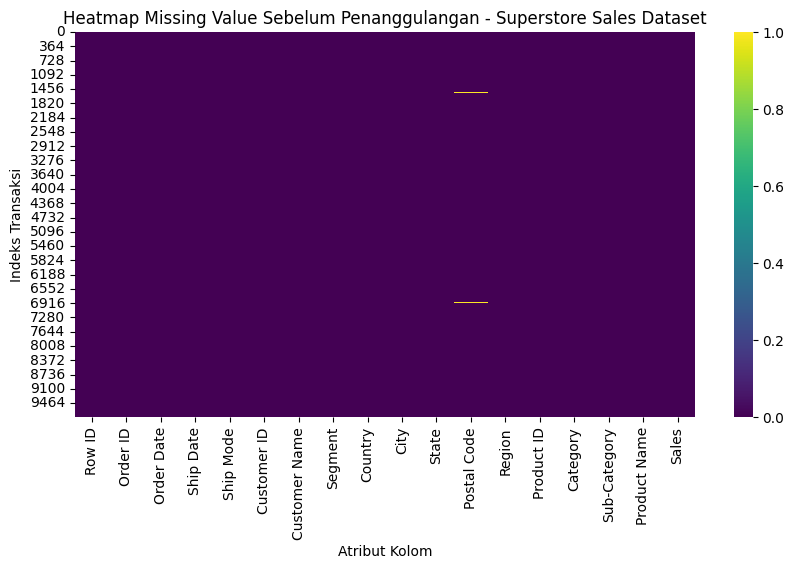

In [11]:
plt.figure(figsize=(10, 5))
sns.heatmap(df.isnull(), cbar=True, cmap='viridis')
plt.title('Heatmap Missing Value Sebelum Penanggulangan - Superstore Sales Dataset')
plt.xlabel('Atribut Kolom')
plt.ylabel('Indeks Transaksi')
plt.show()


### 12. Penanggulangan Missing Value (Imputasi Modus Postal Code)
Mengatasi nilai kosong pada atribut Postal Code dengan menerapkan teknik imputasi data berbasis modus (kode pos yang paling sering muncul).


In [12]:
modus_postal = df['Postal Code'].mode()[0]
df['Postal Code'] = df['Postal Code'].fillna(modus_postal)

print(f"Nilai Modus Postal Code yang Digunakan: {modus_postal}")
print("Jumlah Missing Value Postal Code Setelah Penanggulangan:", df['Postal Code'].isnull().sum())
print("Total Missing Value Keseluruhan Setelah Penanggulangan:", df.isnull().sum().sum())


Nilai Modus Postal Code yang Digunakan: 10035.0
Jumlah Missing Value Postal Code Setelah Penanggulangan: 0
Total Missing Value Keseluruhan Setelah Penanggulangan: 0


### 13. Visualisasi Heatmap Missing Value Pasca Penanggulangan
Menampilkan kembali visualisasi Heatmap untuk memverifikasi secara empiris bahwa dataset telah bersih 100% dari nilai kosong.


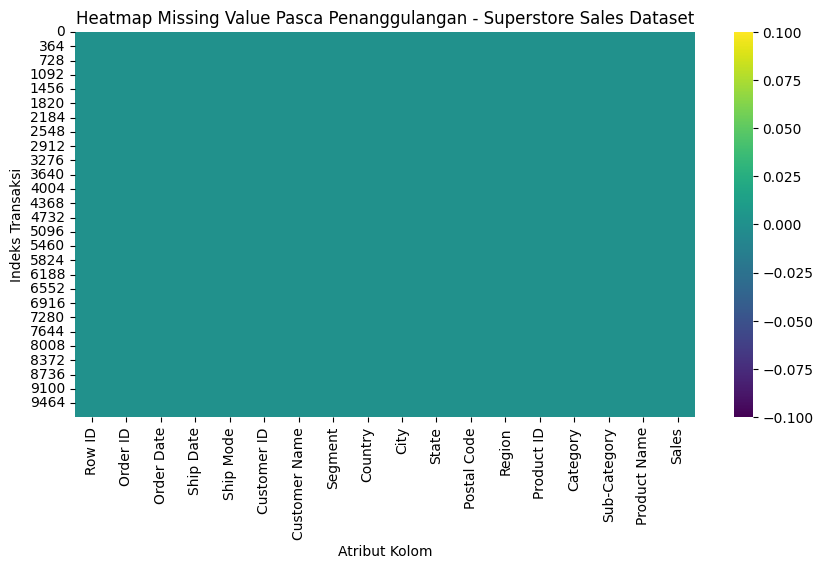

In [13]:
plt.figure(figsize=(10, 5))
sns.heatmap(df.isnull(), cbar=True, cmap='viridis')
plt.title('Heatmap Missing Value Pasca Penanggulangan - Superstore Sales Dataset')
plt.xlabel('Atribut Kolom')
plt.ylabel('Indeks Transaksi')
plt.show()


### 14. Cek Jumlah Duplikat Data
Memeriksa apakah terdapat baris duplikat penuh pada data transaksi penjualan.



In [14]:
jumlah_duplikat = df.duplicated().sum()
print("Jumlah Baris Duplikat:", jumlah_duplikat)


Jumlah Baris Duplikat: 17


### 15. Cek Jumlah Pesanan Unik (Order ID)
Menghitung total lembar faktur/pesanan belanja unik (`Order ID`) dari seluruh 9.818 baris transaksi, serta membuktikan bagaimana angka 4.922 dihitung dari pengelompokan data transaksi.


In [15]:
# Menghitung total lembar pesanan unik menggunakan fungsi nunique()
pesanan_unik = df['Order ID'].nunique()
total_baris = len(df)
rata_rata_item = total_baris / pesanan_unik

print("=== PEMBUKTIAN PERHITUNGAN PESANAN UNIK ===")
print(f"Total Baris Item Transaksi : {total_baris} baris")
print(f"Jumlah Pesanan Unik (Order) : {pesanan_unik} pesanan")
print(f"Rata-rata Barang per Pesanan: {rata_rata_item:.2f} barang/pesanan\n")

# Penjelasan: 1 nomor Order ID dapat memuat banyak item belanjaan
print("Contoh 5 Nomor Pesanan dengan Jumlah Barang Terbanyak dalam 1 Transaksi:")
display(df['Order ID'].value_counts().head(5).to_frame(name='Jumlah Item Belanja dalam 1 Struk'))


=== PEMBUKTIAN PERHITUNGAN PESANAN UNIK ===
Total Baris Item Transaksi : 9818 baris
Jumlah Pesanan Unik (Order) : 4922 pesanan
Rata-rata Barang per Pesanan: 1.99 barang/pesanan

Contoh 5 Nomor Pesanan dengan Jumlah Barang Terbanyak dalam 1 Transaksi:


,Jumlah Item Belanja dalam 1 Struk
Order ID,
CA-2018-100111,14
CA-2018-157987,12
US-2017-108504,11
CA-2017-165330,11
CA-2016-131338,10


### 16. Distribusi Kategori Produk
Melihat sebaran frekuensi transaksi berdasarkan kategori produk ritel.



In [16]:
kategori = df['Category'].value_counts().to_frame(name='Jumlah Transaksi')
kategori['Persentase (%)'] = (kategori['Jumlah Transaksi'] / len(df) * 100).round(2)
display(kategori)


,Jumlah Transaksi,Persentase (%)
Category,,
Office Supplies,5919,60.29
Furniture,2082,21.21
Technology,1817,18.51


### 17. Pemilihan Atribut Nilai Penjualan (Sales) untuk Analisis Outlier
Memilih kolom numerik Sales untuk menganalisis variasi transaksi belanja.



In [17]:
sales = df['Sales']
sales.name = 'Sales_Amount' 


### 18. Statistik Deskriptif Atribut Sales
Melihat nilai rata-rata, standar deviasi, nilai minimum, median, dan maksimum penjualan.



In [18]:
sales.describe().to_frame(name='Statistik Sales ($)')


,Statistik Sales ($)
count,9818.000000
mean,231.199731
std,627.341699
min,0.444000
25%,17.248000
50%,54.432000
75%,210.680000
max,22638.480000


### 19. Visualisasi Boxplot Deteksi Outlier Sales
Menampilkan diagram kotak garis (Boxplot) untuk menganalisis sebaran nilai dan potensi pencilan.



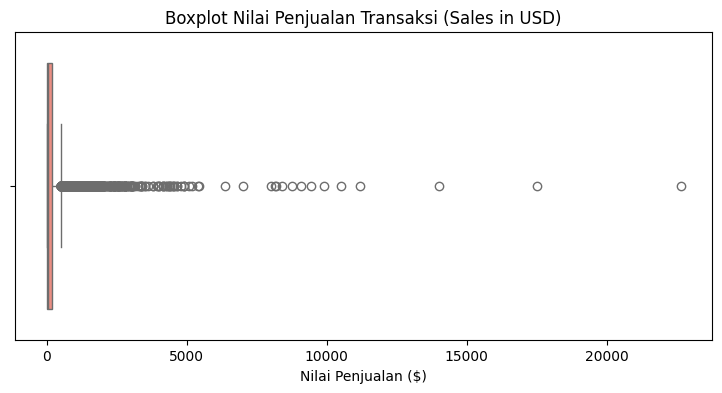

In [19]:
plt.figure(figsize=(9, 4))
sns.boxplot(x=sales, color='salmon')
plt.title('Boxplot Nilai Penjualan Transaksi (Sales in USD)')
plt.xlabel('Nilai Penjualan ($)')
plt.show()


### 20. Perhitungan Kuartil (Q1, Q3) dan Interquartile Range (IQR) Nilai Penjualan (Sales)
Menghitung nilai Kuartil 1 (Q1), Kuartil 3 (Q3), dan Rentang Antarkuartil (IQR) pada atribut Sales untuk memahami sebaran nilai belanja 50% data normal.


In [20]:
# 1. Kuartil Bawah / Q1 (Persentil ke-25):
# Mengurutkan seluruh nilai transaksi Sales dari terendah ke tertinggi,
# lalu mengambil nilai pada posisi 25% data pertama.
Q1 = sales.quantile(0.25)

# 2. Kuartil Atas / Q3 (Persentil ke-75):
# Mengambil nilai pada posisi 75% data terurut.
Q3 = sales.quantile(0.75)

# 3. Interquartile Range (IQR):
# Selisih antara Q3 dan Q1 (IQR = Q3 - Q1).
# Mengukur rentang penyebaran 50% transaksi belanja di area tengah (data normal).
IQR = Q3 - Q1

print("=== HASIL PERHITUNGAN KUARTIL & IQR SALES ===") 
print(f"Q1 (Kuartil Bawah / 25%)  : ${Q1:.2f} -> 25% transaksi bernilai belanja <= ${Q1:.2f}")
print(f"Q3 (Kuartil Atas / 75%)   : ${Q3:.2f} -> 75% transaksi bernilai belanja <= ${Q3:.2f}")
print(f"IQR (Rentang Antarkuartil): ${IQR:.2f} -> Rentang nilai belanja 50% transaksi normal (${Q1:.2f} s.d. ${Q3:.2f})")


=== HASIL PERHITUNGAN KUARTIL & IQR SALES ===
Q1 (Kuartil Bawah / 25%)  : $17.25 -> 25% transaksi bernilai belanja <= $17.25
Q3 (Kuartil Atas / 75%)   : $210.68 -> 75% transaksi bernilai belanja <= $210.68
IQR (Rentang Antarkuartil): $193.43 -> Rentang nilai belanja 50% transaksi normal ($17.25 s.d. $210.68)


### 21. Perhitungan Batas Atas Outlier Sales (Metode John Tukey)
Menentukan ambang batas atas toleransi belanja normal menggunakan rumus standar statistik John Tukey: Q3 + (1.5 * IQR).


In [21]:
# Rumus Batas Atas Outlier John Tukey: Q3 + (1.5 * IQR)
# Setiap transaksi yang nilainya melebihi angka ini dikategorikan secara statistik sebagai Outlier (Pencilan)
pengali_iqr = 1.5 * IQR
batas_atas = Q3 + pengali_iqr

print("=== PERHITUNGAN AMBANG BATAS ATAS OUTLIER SALES ===") 
print(f"Rumus Statistik : Q3 + (1.5 * IQR)")
print(f"Langkah Hitung  : ${Q3:.2f} + (1.5 * ${IQR:.2f})")
print(f"                : ${Q3:.2f} + ${pengali_iqr:.2f}")
print(f"Batas Atas      : ${batas_atas:.2f}")
print(f"Kesimpulan      : Transaksi bernilai belanja di atas ${batas_atas:.2f} diklasifikasikan sebagai Outlier.")


=== PERHITUNGAN AMBANG BATAS ATAS OUTLIER SALES ===
Rumus Statistik : Q3 + (1.5 * IQR)
Langkah Hitung  : $210.68 + (1.5 * $193.43)
                : $210.68 + $290.15
Batas Atas      : $500.83
Kesimpulan      : Transaksi bernilai belanja di atas $500.83 diklasifikasikan sebagai Outlier.


### 22. Jumlah Transaksi Terdeteksi Outlier Sales
Menghitung total transaksi belanja ritel yang melampaui batas ambang atas toleransi ($500.83).


In [22]:
# Memfilter transaksi dengan nilai Sales melebihi ambang batas atas ($500.83)
outliers = df[df['Sales'] > batas_atas]
persentase_outlier = (len(outliers) / len(df)) * 100

print("=== HASIL DETEKSI TRANSAKSI OUTLIER SALES ===") 
print(f"Jumlah Transaksi Outlier : {len(outliers)} transaksi")
print(f"Persentase Outlier       : {persentase_outlier:.2f}% dari total {len(df)} transaksi")
print(f"Rentang Nilai Outlier    : ${outliers['Sales'].min():.2f} s.d. ${outliers['Sales'].max():.2f}")


=== HASIL DETEKSI TRANSAKSI OUTLIER SALES ===
Jumlah Transaksi Outlier : 1149 transaksi
Persentase Outlier       : 11.70% dari total 9818 transaksi
Rentang Nilai Outlier    : $501.81 s.d. $22638.48


### 23. Daftar 10 Transaksi dengan Nilai Belanja Tertinggi
Menampilkan 10 transaksi teratas dengan nilai belanja moneter paling ekstrem.



In [23]:
outliers[['Order ID', 'Customer Name', 'Category', 'Product Name', 'Sales']].sort_values(by='Sales', ascending=False).head(10)


,Order ID,Customer Name,Category,Product Name,Sales
2697,CA-2015-145317,Sean Miller,Technology,Cisco TelePresence System EX90 Videoconferenci...,22638.480
6826,CA-2017-118689,Tamara Chand,Technology,Canon imageCLASS 2200 Advanced Copier,17499.950
8153,CA-2018-140151,Raymond Buch,Technology,Canon imageCLASS 2200 Advanced Copier,13999.960
2623,CA-2018-127180,Tom Ashbrook,Technology,Canon imageCLASS 2200 Advanced Copier,11199.968
4190,CA-2018-166709,Hunter Lopez,Technology,Canon imageCLASS 2200 Advanced Copier,10499.970
9039,CA-2017-117121,Adrian Barton,Office Supplies,GBC Ibimaster 500 Manual ProClick Binding System,9892.740
4098,CA-2015-116904,Sanjit Chand,Office Supplies,Ibico EPK-21 Electric Binding System,9449.950
4277,US-2017-107440,Bill Shonely,Technology,"3D Systems Cube Printer, 2nd Generation, Magenta",9099.930
8488,CA-2017-158841,Sanjit Engle,Technology,HP Designjet T520 Inkjet Large Format Printer ...,8749.950
6425,CA-2017-143714,Christopher Conant,Technology,Canon imageCLASS 2200 Advanced Copier,8399.976
